In [1]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [2]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure4"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [3]:
from IPython.display import display


In [4]:
# --- config (adjust if needed) ---
import os, glob, math
import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    log_loss, brier_score_loss
)

EXP        = "Feature_augmentation_experiment"   # your experiment folder
TASK       = "binary"
MODEL_TYPE = "tabm"
PRED_ROOT  = f"predictions/{EXP}/{TASK}"
ALWAYS_ON  = "Text_Embedding"
VARIABLES  = ["Proteomics","ECFP","CellPaint","MIC","GC"]  # players
VALUE_METRIC = "pr_auc"
THRESHOLD    = 0.5
OUT_DIR      = f"./analysis_exports/Feature_augmentation_experiment/Shapley"
os.makedirs(OUT_DIR, exist_ok=True)




In [5]:

def split_runname_by_model(run_name: str, model_type: str):
    marker = f"_{model_type}_"
    if marker not in run_name:
        return None
    prefix, modalities = run_name.split(marker, 1)
    if "_" not in prefix:
        return None
    aug, llm = prefix.split("_", 1)
    return aug, llm, modalities

def read_one_run_dir(run_dir: str):
    frames = []
    for pf in glob.glob(os.path.join(run_dir, "*.pkl")):
        try:
            df = pd.read_pickle(pf)
        except Exception:
            continue
        needed = {"True","ProbaPos","cv_iter","fold_idx","rep_idx"}
        if not needed.issubset(df.columns):
            continue
        keep = ["True","Pred","ProbaPos","cv_iter","fold_idx","rep_idx"]
        for k in keep:
            if k not in df.columns:
                df[k] = np.nan
        frames.append(df[keep].copy())
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def compute_metrics_from_df(df, prob_col="ProbaPos", pred_col="Pred", thr=0.5):
    y_true = df["True"].astype(int).values
    if pred_col in df.columns and df[pred_col].notna().any():
        y_pred = df[pred_col].fillna((df[prob_col] >= thr).astype(int) if prob_col in df.columns else 0).astype(int).values
    else:
        if prob_col not in df.columns:
            raise ValueError("Need Pred or ProbaPos to compute metrics.")
        y_pred = (df[prob_col].values >= thr).astype(int)
    mets = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    if prob_col in df.columns:
        y_score = df[prob_col].values
        try: mets["roc_auc"] = roc_auc_score(y_true, y_score)
        except Exception: mets["roc_auc"] = np.nan
        try: mets["pr_auc"]  = average_precision_score(y_true, y_score)
        except Exception: mets["pr_auc"]  = np.nan
        try: mets["log_loss"] = log_loss(y_true, y_score, eps=1e-15)
        except Exception: mets["log_loss"] = np.nan
        try: mets["brier"] = brier_score_loss(y_true, y_score)
        except Exception: mets["brier"] = np.nan
    else:
        mets.update({"roc_auc": np.nan, "pr_auc": np.nan, "log_loss": np.nan, "brier": np.nan})
    return mets

def parse_atomic_features(modalities: str):
    return frozenset(m.strip() for m in modalities.split("+") if m.strip())



import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

def plot_shapley(shap_df: pd.DataFrame, title: str = "Feature importance (Shapley)",
                 figsize=(6, 3.5), annotate=True, savepath=None):
    """
    Plot horizontal bars of Shapley values.
    Expects columns: 'feature', 'shapley'.

    Parameters
    ----------
    shap_df : pd.DataFrame
        Must contain columns ['feature', 'shapley'].
    title : str
        Plot title.
    figsize : tuple
        Figure size (width, height) in inches.
    annotate : bool
        If True, prints the numeric Shapley value at the end of each bar.
    savepath : str or None
        If provided, saves the figure to this path.
    """
    df = shap_df.copy()
    # sort by shapley value
    df = df.sort_values("shapley", ascending=True)

    palette = sns.color_palette("mako", n_colors=len(df))
    color_map = {feat: palette[i] for i, feat in enumerate(df["feature"]) }

    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(df["feature"], df["shapley"], color=[color_map[f] for f in df["feature"]])
    ax.axvline(0.0, linestyle="--", linewidth=1)
    ax.set_xlabel("Shapley value (contribution to payoff)")
    ax.set_ylabel("Feature")
    ax.set_title(title)
    ax.set_xlim(df["shapley"].min() - 0.05, df["shapley"].max() + 0.05)
    ax.grid(True, axis="x", alpha=0.3)

    if annotate:
        for y, v in enumerate(df["shapley"].values):
            ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:.3f}",
                    va="center", ha="left" if v >= 0 else "right")

    plt.tight_layout()
    if savepath:
        save_figure(plt.gcf(), savepath, dpi=200, bbox_inches="tight")
    plt.show()


In [6]:
# 1) discover runs (you already saw 32)
runs = []
for d in sorted(os.listdir(PRED_ROOT)):
    run_dir = os.path.join(PRED_ROOT, d)
    if not os.path.isdir(run_dir):
        continue
    parsed = split_runname_by_model(d, MODEL_TYPE)
    if parsed is None:
        continue
    aug, llm, modalities = parsed
    runs.append({"run_dir": run_dir, "run_name": d, "aug": aug, "llm": llm, "modalities": modalities})
print(f"Found runs: {len(runs)}")

Found runs: 32


In [7]:


# 2) per-resample metrics per run
rows = []
for r in runs:
    df = read_one_run_dir(r["run_dir"])
    if df.empty:
        continue
    df["cv_iter"]  = df["cv_iter"].astype(int)
    df["fold_idx"] = df["fold_idx"].astype(int)
    df["rep_idx"]  = df["rep_idx"].astype(int)
    df["resample_id"] = df["cv_iter"].astype(str) + "-" + df["fold_idx"].astype(str) + "-" + df["rep_idx"].astype(str)
    for rid, chunk in df.groupby("resample_id"):
        mets = compute_metrics_from_df(chunk, prob_col="ProbaPos", pred_col="Pred", thr=THRESHOLD)
        rows.append({
            "model": MODEL_TYPE,
            "run_name": r["run_name"],
            "modalities": r["modalities"],
            "features": parse_atomic_features(r["modalities"]),
            "resample_id": rid,
            **mets
        })

per_resample_df = pd.DataFrame(rows)
per_resample_df.to_csv(os.path.join(OUT_DIR, f"{MODEL_TYPE}_per_resample_metrics.csv"), index=False)



/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2910: FutureWarning: Setting the eps parameter is deprecated and will be removed in 1.5. Instead eps will always havea default value of `np.finfo(y_pred.dtype).eps`.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2910: FutureWarning: Setting the eps parameter is deprecated and will be removed in 1.5. Instead eps will always havea default value of `np.finfo(y_pred.dtype).eps`.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2910: FutureWarning: Setting the eps parameter is deprecated and will be removed in 1.5. Instead eps will always havea default value of `np.finfo(y_pred.dtype).eps`.
  warnings.warn(
/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2910: FutureWarning: Setting the eps parameter is deprecated and will be removed in 1.5. Instead eps will always havea default value of `np.finfo(y_pre

In [8]:
# 3) aggregate to coalition values
per_run_values = (per_resample_df
                  .groupby(["model","run_name","features"], as_index=False)[VALUE_METRIC]
                  .mean()
                  .rename(columns={VALUE_METRIC: "value"}))

coalition_values = (per_run_values
                    .groupby(["model","features"], as_index=False)["value"]
                    .mean())




In [9]:
# 4) strip Text_Embedding (always-on) -> variable coalitions
coalition_values["var_features"] = coalition_values["features"].apply(
    lambda s: frozenset([a for a in s if a != ALWAYS_ON])
)
var_values = (coalition_values
              .groupby(["var_features"], as_index=False)["value"]
              .mean())



In [10]:
# 5) sanity check: completeness over 5 variables (should be 32)
def all_subsets(items):
    items = list(items)
    subs = []
    for k in range(len(items)+1):
        for c in combinations(items, k):
            subs.append(frozenset(c))
    return subs

atoms = VARIABLES[:]  # ensure order is fixed
all_coals = all_subsets(atoms)
value_map = {frozenset(r["var_features"]): r["value"] for _, r in var_values.iterrows()}
missing = [C for C in all_coals if C not in value_map]
print(f"Have {len(value_map)} / {len(all_coals)} coalitions. Missing: {len(missing)}")
assert not missing, "Exact Shapley requires all coalitions; one or more are still missing."



Have 32 / 32 coalitions. Missing: 0


,var_features,value
24,"(ECFP, CellPaint, Proteomics)",0.957473
31,"(Proteomics, ECFP, GC, MIC, CellPaint)",0.956946
26,"(ECFP, CellPaint, Proteomics, GC)",0.956783
25,"(ECFP, MIC, CellPaint, Proteomics)",0.956126
21,"(ECFP, Proteomics, GC)",0.953507
20,"(ECFP, Proteomics, MIC)",0.953120
28,"(ECFP, MIC, Proteomics, GC)",0.952886
18,"(ECFP, Proteomics)",0.952000
30,"(CellPaint, Proteomics, MIC)",0.927920
22,"(CellPaint, MIC, Proteomics, GC)",0.927836


,feature,shapley
0,Proteomics,0.259678
1,ECFP,0.250560
2,CellPaint,0.226260
3,MIC,0.046894
4,GC,0.030617


Saved CSVs in: ./analysis_exports/Feature_augmentation_experiment/Shapley


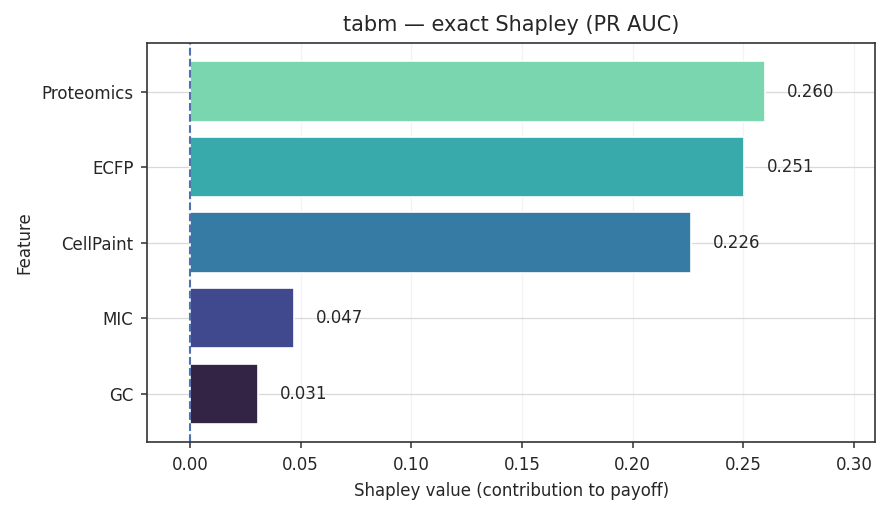

In [11]:
# 6) exact shapley
def exact_shapley_from_values(value_map, atoms):
    n = len(atoms)
    fact = math.factorial
    shap = {a: 0.0 for a in atoms}
    for k in range(n):
        for S in combinations(atoms, k):
            S = set(S)
            vS = value_map[frozenset(S)]
            for a in atoms:
                if a in S:
                    continue
                Sa = frozenset(S | {a})
                vSa = value_map[Sa]
                weight = fact(len(S)) * fact(n - len(S) - 1) / fact(n)
                shap[a] += weight * (vSa - vS)
    return pd.DataFrame({"feature": atoms, "shapley": [shap[a] for a in atoms]})\
             .sort_values("shapley", ascending=False)

shap_exact_df = exact_shapley_from_values(value_map, atoms)
shap_exact_df.to_csv(os.path.join(OUT_DIR, f"{MODEL_TYPE}_shapley_exact_{VALUE_METRIC}.csv"), index=False)
coalition_values.to_csv(os.path.join(OUT_DIR, f"{MODEL_TYPE}_coalition_values.csv"), index=False)

display(var_values.sort_values("value", ascending=False).head(10))
display(shap_exact_df)
print("Saved CSVs in:", OUT_DIR)
plot_shapley(shap_exact_df, title=f"{MODEL_TYPE} — exact Shapley ({VALUE_METRIC.replace("_", " " ).upper()})", savepath="figure4_shapley")
